/var/folders/sv/2j0ks0gx2n37tvl2glchkw900000gp/T/ipykernel_63267/2302847469.py:59: RuntimeWarning: invalid value encountered in divide
  grid_smooth = np.where(ws > 0, gs / ws, np.nan)


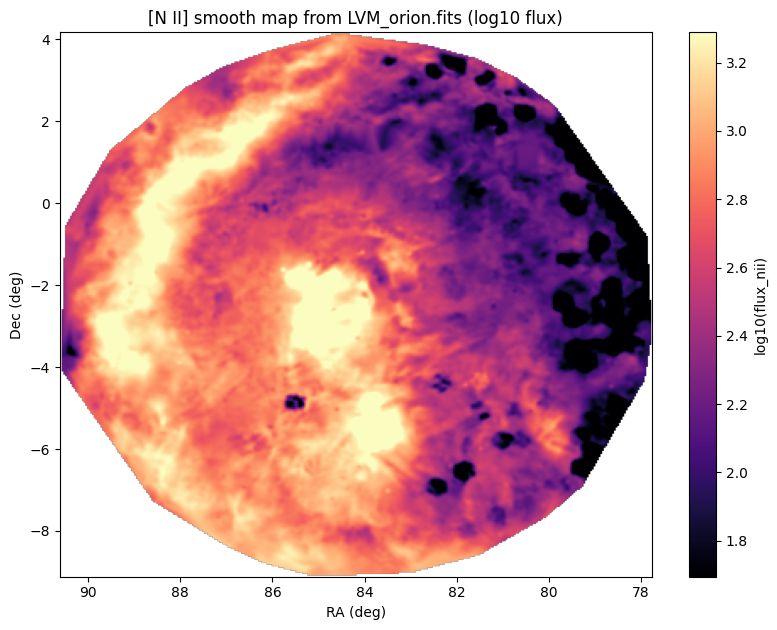

In [64]:
# Smoothed [N II] map from LVM_orion.fits (fallback: LVM_Orion.fits)
from pathlib import Path
from astropy.io import fits
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import griddata
from scipy.ndimage import gaussian_filter
from scipy.spatial import Delaunay

candidates = [Path('LVM_orion.fits'), Path('LVM_Orion.fits')]
fits_path = next((p for p in candidates if p.exists()), None)
if fits_path is None:
    raise FileNotFoundError('Could not find LVM_orion.fits or LVM_Orion.fits in current folder.')

with fits.open(fits_path) as hdul:
    table_hdu = None
    for h in hdul:
        if isinstance(h, (fits.BinTableHDU, fits.TableHDU)) and h.data is not None:
            names = [n.lower() for n in h.data.names] if h.data.names is not None else []
            if {'ra', 'dec'}.issubset(names) and 'flux_nii' in names:
                table_hdu = h
                break

    if table_hdu is not None:
        data = table_hdu.data
        cols = {n.lower(): n for n in data.names}
        ra = np.asarray(data[cols['ra']], dtype=float)
        dec = np.asarray(data[cols['dec']], dtype=float)
        flux_nii = np.asarray(data[cols['flux_nii']], dtype=float)

        mask = np.isfinite(ra) & np.isfinite(dec) & np.isfinite(flux_nii) & (flux_nii > 0)
        ra = ra[mask]
        dec = dec[mask]
        logf = np.log10(flux_nii[mask])

        # Build regular sky grid and interpolate scattered fibers to a smooth map
        nx, ny = 350, 350
        gx = np.linspace(np.min(ra), np.max(ra), nx)
        gy = np.linspace(np.min(dec), np.max(dec), ny)
        GRA, GDEC = np.meshgrid(gx, gy)

        points = np.column_stack((ra, dec))
        q = np.column_stack((GRA.ravel(), GDEC.ravel()))

        # Keep only map pixels inside the convex hull of observed fibers
        hull = Delaunay(points)
        inside_hull = (hull.find_simplex(q) >= 0).reshape(GRA.shape)

        grid_linear = griddata(points, logf, (GRA, GDEC), method='linear')
        grid_nearest = griddata(points, logf, (GRA, GDEC), method='nearest')
        grid = np.where(inside_hull, np.where(np.isfinite(grid_linear), grid_linear, grid_nearest), np.nan)

        # NaN-aware Gaussian smoothing to avoid bleeding from masked regions
        sigma_pix = 1.0
        w = np.isfinite(grid).astype(float)
        g0 = np.nan_to_num(grid, nan=0.0)
        gs = gaussian_filter(g0, sigma=sigma_pix)
        ws = gaussian_filter(w, sigma=sigma_pix)
        grid_smooth = np.where(ws > 0, gs / ws, np.nan)
        grid_smooth = np.where(inside_hull, grid_smooth, np.nan)

        finite_vals = grid_smooth[np.isfinite(grid_smooth)]
        vmin, vmax = np.nanpercentile(finite_vals, [5, 95])

        plt.figure(figsize=(8.2, 6.4))
        plt.imshow(
            grid_smooth, origin='lower', cmap='magma', vmin=vmin, vmax=vmax,
            extent=[gx.min(), gx.max(), gy.min(), gy.max()], aspect='auto'
        )
        plt.gca().invert_xaxis()
        plt.xlabel('RA (deg)')
        plt.ylabel('Dec (deg)')
        plt.title(f'[N II] smooth map from {fits_path.name} (log10 flux)')
        plt.colorbar(label='log10(flux_nii)')
        plt.tight_layout()
        plt.show()
    else:
        # Fallback: smooth first 2D image extension if no RA/Dec+flux_nii table is present
        img = None
        for h in hdul:
            if h.data is not None and getattr(h.data, 'ndim', 0) == 2:
                img = np.asarray(h.data, dtype=float)
                break
        if img is None:
            raise ValueError('No suitable RA/Dec/flux_nii table or 2D image found in FITS file.')

        vals = img[np.isfinite(img)]
        vmin, vmax = np.nanpercentile(vals, [5, 95])
        img_smooth = gaussian_filter(img, sigma=1.0)

        plt.figure(figsize=(7.5, 6))
        plt.imshow(img_smooth, origin='lower', cmap='magma', vmin=vmin, vmax=vmax)
        plt.title(f'Smoothed 2D map from {fits_path.name} (fallback view)')
        plt.colorbar(label='Intensity')
        plt.tight_layout()
        plt.show()

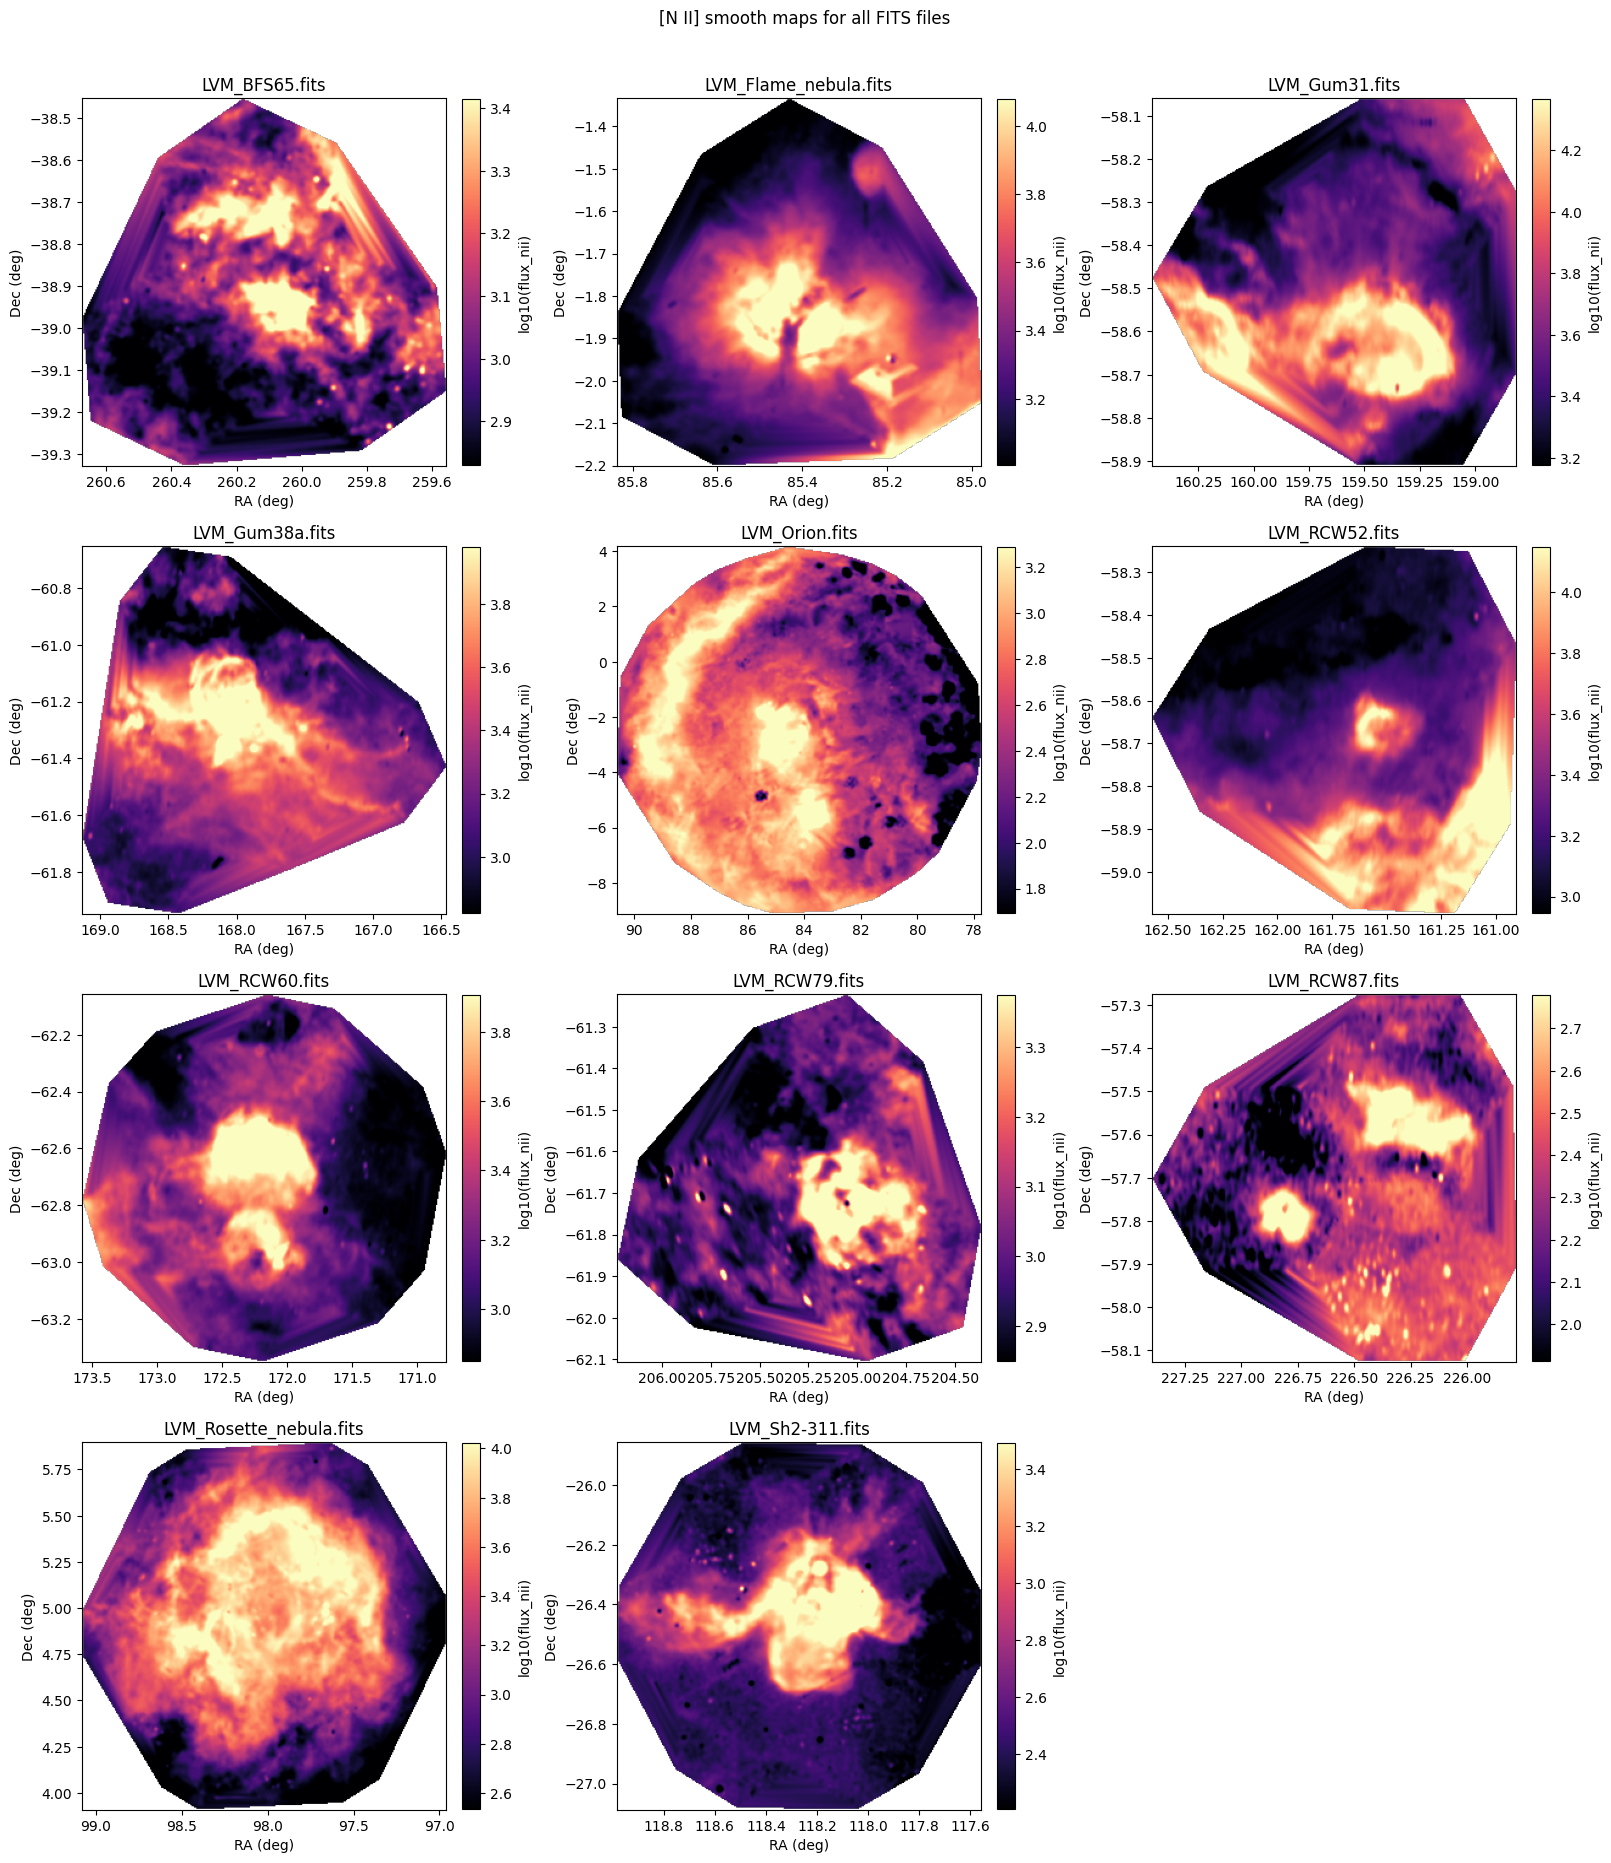

Plotted 11 / 12 FITS files with usable [N II] data.


In [67]:
# Multi-panel [N II] smooth maps for all FITS files in current folder
from pathlib import Path
import math
from astropy.io import fits
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import griddata
from scipy.ndimage import gaussian_filter
from scipy.spatial import Delaunay

fits_files = sorted(Path('.').glob('*.fits'))
if len(fits_files) == 0:
    raise FileNotFoundError('No FITS files found in current folder.')

def make_smooth_nii_map(fits_path, nx=300, ny=300, sigma_pix=1.0):
    with fits.open(fits_path) as hdul:
        table_hdu = None
        for h in hdul:
            if isinstance(h, (fits.BinTableHDU, fits.TableHDU)) and h.data is not None and h.data.names is not None:
                names = [n.lower() for n in h.data.names]
                if {'ra', 'dec'}.issubset(names) and 'flux_nii' in names:
                    table_hdu = h
                    break

        if table_hdu is None:
            return None

        data = table_hdu.data
        cols = {n.lower(): n for n in data.names}
        ra = np.asarray(data[cols['ra']], dtype=float)
        dec = np.asarray(data[cols['dec']], dtype=float)
        flux_nii = np.asarray(data[cols['flux_nii']], dtype=float)

        m = np.isfinite(ra) & np.isfinite(dec) & np.isfinite(flux_nii) & (flux_nii > 0)
        if np.count_nonzero(m) < 10:
            return None

        ra = ra[m]
        dec = dec[m]
        logf = np.log10(flux_nii[m])

        gx = np.linspace(np.min(ra), np.max(ra), nx)
        gy = np.linspace(np.min(dec), np.max(dec), ny)
        GRA, GDEC = np.meshgrid(gx, gy)

        points = np.column_stack((ra, dec))
        q = np.column_stack((GRA.ravel(), GDEC.ravel()))

        hull = Delaunay(points)
        inside_hull = (hull.find_simplex(q) >= 0).reshape(GRA.shape)

        grid_linear = griddata(points, logf, (GRA, GDEC), method='linear')
        grid_nearest = griddata(points, logf, (GRA, GDEC), method='nearest')
        grid = np.where(inside_hull, np.where(np.isfinite(grid_linear), grid_linear, grid_nearest), np.nan)

        # NaN-aware smoothing with safe divide
        w = np.isfinite(grid).astype(float)
        g0 = np.nan_to_num(grid, nan=0.0)
        gs = gaussian_filter(g0, sigma=sigma_pix)
        ws = gaussian_filter(w, sigma=sigma_pix)
        grid_smooth = np.full_like(gs, np.nan, dtype=float)
        np.divide(gs, ws, out=grid_smooth, where=ws > 0)
        grid_smooth = np.where(inside_hull, grid_smooth, np.nan)

        vals = grid_smooth[np.isfinite(grid_smooth)]
        if vals.size == 0:
            return None
        vmin, vmax = np.nanpercentile(vals, [5, 95])

        return {
            'map': grid_smooth,
            'extent': [gx.min(), gx.max(), gy.min(), gy.max()],
            'vmin': vmin,
            'vmax': vmax,
        }

results = []
for fp in fits_files:
    try:
        r = make_smooth_nii_map(fp)
    except Exception:
        r = None
    results.append((fp.name, r))

valid = [(name, r) for name, r in results if r is not None]
if len(valid) == 0:
    raise ValueError('No FITS file with usable RA/Dec/flux_nii table found.')

n = len(valid)
ncols = min(3, n)
nrows = math.ceil(n / ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(5.4 * ncols, 4.6 * nrows), squeeze=False)

for k, (name, r) in enumerate(valid):
    i = k // ncols
    j = k % ncols
    ax = axes[i, j]
    im = ax.imshow(
        r['map'], origin='lower', cmap='magma',
        vmin=r['vmin'], vmax=r['vmax'],
        extent=r['extent'], aspect='auto'
    )
    ax.invert_xaxis()
    ax.set_title(name)
    ax.set_xlabel('RA (deg)')
    ax.set_ylabel('Dec (deg)')
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label='log10(flux_nii)')

# Hide any extra empty panels
for k in range(len(valid), nrows * ncols):
    i = k // ncols
    j = k % ncols
    axes[i, j].axis('off')

fig.suptitle('[N II] smooth maps for all FITS files', y=1.01)
plt.tight_layout()
plt.show()

print(f'Plotted {len(valid)} / {len(fits_files)} FITS files with usable [N II] data.')

In [26]:
import numpy as np
import matplotlib.pyplot as plt

Max |v_front + v_back| = 0.000e+00 km/s
Expected: 0 everywhere when v_bulk_los=0 and front/back weights are equal.


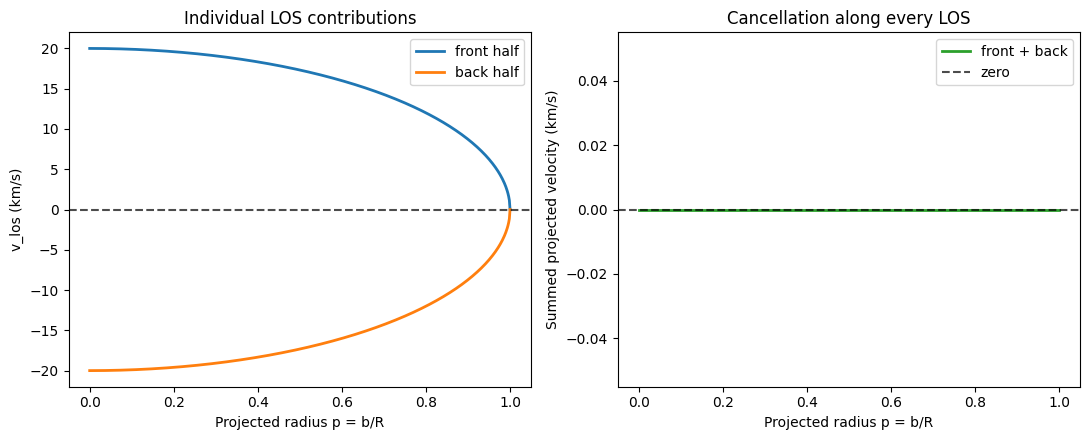

In [28]:
# Symmetric expanding shell: front and back LOS components cancel when added.
# Assumptions: same weighting from both halves (equal emissivity/path contribution),
# no extinction asymmetry, and no bulk LOS motion.

v_exp = 20.0      # km/s
v_bulk_los = 0.0  # km/s; keep 0.0 for exact cancellation

p = np.linspace(0.0, 1.0, 600)      # projected radius b/R
mu = np.sqrt(1.0 - p**2)             # cos(theta) along the shell

# LOS components from the two intersection points of the shell
v_front = v_bulk_los + v_exp * mu
v_back  = v_bulk_los - v_exp * mu

# Unweighted sum along each line of sight
v_sum = v_front + v_back

print(f"Max |v_front + v_back| = {np.max(np.abs(v_sum)):.3e} km/s")
print("Expected: 0 everywhere when v_bulk_los=0 and front/back weights are equal.")

fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))

# Panel 1: individual front/back projected velocities
ax[0].plot(p, v_front, lw=2, label="front half")
ax[0].plot(p, v_back, lw=2, label="back half")
ax[0].axhline(0, color="k", ls="--", alpha=0.7)
ax[0].set_xlabel("Projected radius p = b/R")
ax[0].set_ylabel("v_los (km/s)")
ax[0].set_title("Individual LOS contributions")
ax[0].legend()

# Panel 2: summed projected velocity along each LOS
ax[1].plot(p, v_sum, lw=2, color="tab:green", label="front + back")
ax[1].axhline(0, color="k", ls="--", alpha=0.7, label="zero")
ax[1].set_xlabel("Projected radius p = b/R")
ax[1].set_ylabel("Summed projected velocity (km/s)")
ax[1].set_title("Cancellation along every LOS")
ax[1].legend()

plt.tight_layout()
plt.show()

Max |summed map| inside shell = 0.000e+00 km/s


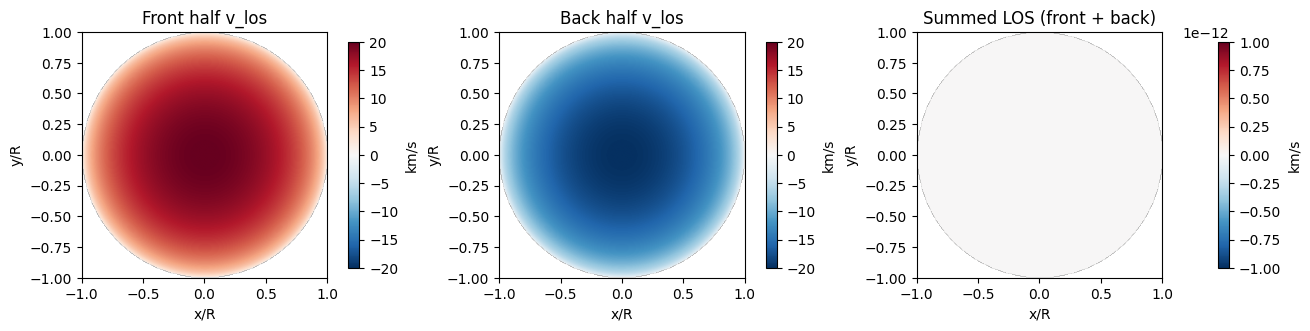

In [29]:
# imshow view of projected LOS velocities across the shell on the sky plane
v_exp = 20.0      # km/s
v_bulk_los = 0.0  # km/s
npix = 300

# Sky-plane coordinates normalized by shell radius R
x = np.linspace(-1.0, 1.0, npix)
y = np.linspace(-1.0, 1.0, npix)
X, Y = np.meshgrid(x, y)
r2 = X**2 + Y**2
inside = r2 <= 1.0

# cos(theta) on the shell intersections along each LOS
mu_map = np.zeros_like(X)
mu_map[inside] = np.sqrt(1.0 - r2[inside])

# Front/back LOS components and their sum
v_front_map = np.full_like(X, np.nan, dtype=float)
v_back_map = np.full_like(X, np.nan, dtype=float)
v_sum_map = np.full_like(X, np.nan, dtype=float)

v_front_map[inside] = v_bulk_los + v_exp * mu_map[inside]
v_back_map[inside] = v_bulk_los - v_exp * mu_map[inside]
v_sum_map[inside] = v_front_map[inside] + v_back_map[inside]

print(f"Max |summed map| inside shell = {np.nanmax(np.abs(v_sum_map)):.3e} km/s")

fig, ax = plt.subplots(1, 3, figsize=(13, 4.2), constrained_layout=True)
extent = [-1, 1, -1, 1]

im0 = ax[0].imshow(v_front_map, origin="lower", extent=extent, cmap="RdBu_r", vmin=-v_exp, vmax=v_exp)
ax[0].set_title("Front half v_los")
ax[0].set_xlabel("x/R")
ax[0].set_ylabel("y/R")
fig.colorbar(im0, ax=ax[0], fraction=0.046, pad=0.04, label="km/s")

im1 = ax[1].imshow(v_back_map, origin="lower", extent=extent, cmap="RdBu_r", vmin=-v_exp, vmax=v_exp)
ax[1].set_title("Back half v_los")
ax[1].set_xlabel("x/R")
ax[1].set_ylabel("y/R")
fig.colorbar(im1, ax=ax[1], fraction=0.046, pad=0.04, label="km/s")

# Tight limits around 0 so exact cancellation is visually obvious
im2 = ax[2].imshow(v_sum_map, origin="lower", extent=extent, cmap="RdBu_r", vmin=-1e-12, vmax=1e-12)
ax[2].set_title("Summed LOS (front + back)")
ax[2].set_xlabel("x/R")
ax[2].set_ylabel("y/R")
fig.colorbar(im2, ax=ax[2], fraction=0.046, pad=0.04, label="km/s")

for a in ax:
    a.set_aspect("equal")

plt.show()

Target fluctuation RMS delta_v = 4.00 km/s
Measured RMS(front fluct.) = 4.00 km/s
Measured RMS(back fluct.)  = 4.00 km/s
RMS of summed LOS map     = 5.66 km/s


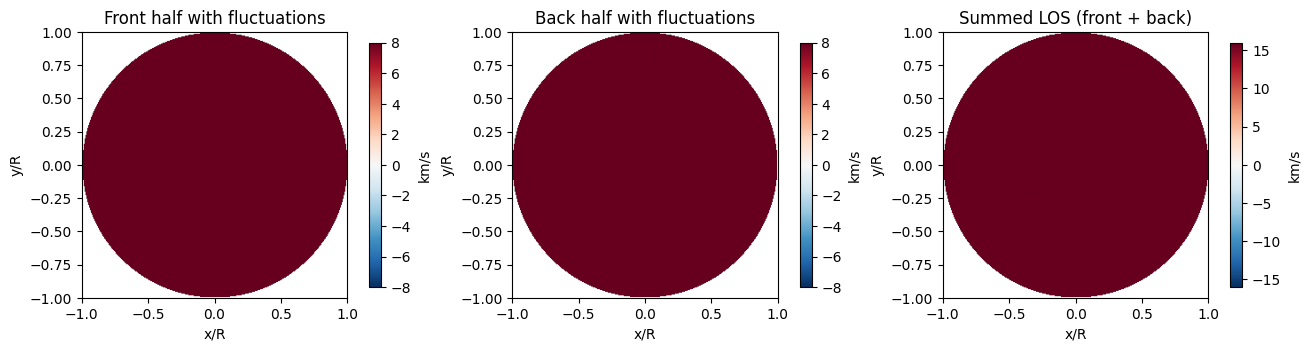

In [32]:
# Same imshow maps, now adding random surface fluctuations with RMS = delta_v
v_exp = 0.0      # km/s
v_bulk_los = 100.0  # km/s
delta_v = 4.0     # km/s, RMS amplitude of random surface fluctuations
npix = 300
seed = 7          # fixed seed for reproducibility

x = np.linspace(-1.0, 1.0, npix)
y = np.linspace(-1.0, 1.0, npix)
X, Y = np.meshgrid(x, y)
r2 = X**2 + Y**2
inside = r2 <= 1.0

mu_map = np.zeros_like(X)
mu_map[inside] = np.sqrt(1.0 - r2[inside])

rng = np.random.default_rng(seed)

# Independent random fluctuations on front/back shell surfaces
dv_front = np.zeros_like(X)
dv_back = np.zeros_like(X)
dv_front[inside] = rng.normal(0.0, delta_v, inside.sum())
dv_back[inside] = rng.normal(0.0, delta_v, inside.sum())

v_front_fluc = np.full_like(X, np.nan, dtype=float)
v_back_fluc = np.full_like(X, np.nan, dtype=float)
v_sum_fluc = np.full_like(X, np.nan, dtype=float)

v_front_fluc[inside] = v_bulk_los + v_exp * mu_map[inside] + dv_front[inside]
v_back_fluc[inside] = v_bulk_los - v_exp * mu_map[inside] + dv_back[inside]
v_sum_fluc[inside] = v_front_fluc[inside] + v_back_fluc[inside]

print(f"Target fluctuation RMS delta_v = {delta_v:.2f} km/s")
print(f"Measured RMS(front fluct.) = {np.std(dv_front[inside]):.2f} km/s")
print(f"Measured RMS(back fluct.)  = {np.std(dv_back[inside]):.2f} km/s")
print(f"RMS of summed LOS map     = {np.std(v_sum_fluc[inside]):.2f} km/s")

fig, ax = plt.subplots(1, 3, figsize=(13, 4.2), constrained_layout=True)
extent = [-1, 1, -1, 1]

im0 = ax[0].imshow(v_front_fluc, origin="lower", extent=extent, cmap="RdBu_r", vmin=-v_exp-2*delta_v, vmax=v_exp+2*delta_v)
ax[0].set_title("Front half with fluctuations")
ax[0].set_xlabel("x/R")
ax[0].set_ylabel("y/R")
fig.colorbar(im0, ax=ax[0], fraction=0.046, pad=0.04, label="km/s")

im1 = ax[1].imshow(v_back_fluc, origin="lower", extent=extent, cmap="RdBu_r", vmin=-v_exp-2*delta_v, vmax=v_exp+2*delta_v)
ax[1].set_title("Back half with fluctuations")
ax[1].set_xlabel("x/R")
ax[1].set_ylabel("y/R")
fig.colorbar(im1, ax=ax[1], fraction=0.046, pad=0.04, label="km/s")

vsum_lim = 4.0 * delta_v
im2 = ax[2].imshow(v_sum_fluc, origin="lower", extent=extent, cmap="RdBu_r", vmin=-vsum_lim, vmax=vsum_lim)
ax[2].set_title("Summed LOS (front + back)")
ax[2].set_xlabel("x/R")
ax[2].set_ylabel("y/R")
fig.colorbar(im2, ax=ax[2], fraction=0.046, pad=0.04, label="km/s")

for a in ax:
    a.set_aspect("equal")

plt.show()

Using full projected disk (r/R <= 1): this is the full 3D sphere surface in projection.
Mean(front LOS) = 66.67 km/s
Mean(back  LOS) = -66.69 km/s
Mean(sum   LOS) = -0.02 km/s


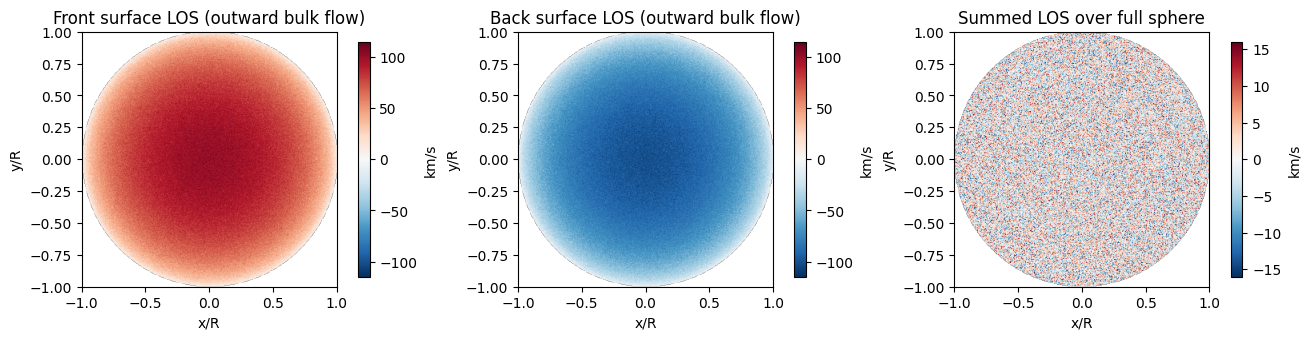

In [34]:
# Full 3D spherical surface (projected to sky): outward radial bulk flow + fluctuations
v_bulk_mag = 100.0   # km/s bulk-flow speed magnitude on sphere surface
delta_v = 4.0        # km/s RMS random fluctuation on front/back surfaces
npix = 320
seed = 11

x = np.linspace(-1.0, 1.0, npix)
y = np.linspace(-1.0, 1.0, npix)
X, Y = np.meshgrid(x, y)
r_proj = np.sqrt(X**2 + Y**2)
inside = r_proj <= 1.0

# Sphere surface intersections along each LOS: z = +/-sqrt(1-r_proj^2)
# For outward radial flow on the sphere, LOS projection is +/-v_bulk_mag*mu.
mu_map = np.zeros_like(X)
mu_map[inside] = np.sqrt(np.clip(1.0 - r_proj[inside]**2, 0.0, None))

rng = np.random.default_rng(seed)
dv_front = np.zeros_like(X)
dv_back = np.zeros_like(X)
dv_front[inside] = rng.normal(0.0, delta_v, inside.sum())
dv_back[inside] = rng.normal(0.0, delta_v, inside.sum())

v_front_surface = np.full_like(X, np.nan, dtype=float)
v_back_surface = np.full_like(X, np.nan, dtype=float)
v_sum_surface = np.full_like(X, np.nan, dtype=float)

v_front_surface[inside] = +v_bulk_mag * mu_map[inside] + dv_front[inside]
v_back_surface[inside]  = -v_bulk_mag * mu_map[inside] + dv_back[inside]
v_sum_surface[inside]   = v_front_surface[inside] + v_back_surface[inside]

print("Using full projected disk (r/R <= 1): this is the full 3D sphere surface in projection.")
print(f"Mean(front LOS) = {np.nanmean(v_front_surface):.2f} km/s")
print(f"Mean(back  LOS) = {np.nanmean(v_back_surface):.2f} km/s")
print(f"Mean(sum   LOS) = {np.nanmean(v_sum_surface):.2f} km/s")

fig, ax = plt.subplots(1, 3, figsize=(13, 4.2), constrained_layout=True)
extent = [-1, 1, -1, 1]
vlim = max(10.0, np.nanmax(np.abs([v_front_surface, v_back_surface])))

im0 = ax[0].imshow(v_front_surface, origin="lower", extent=extent, cmap="RdBu_r", vmin=-vlim, vmax=vlim)
ax[0].set_title("Front surface LOS (outward bulk flow)")
ax[0].set_xlabel("x/R")
ax[0].set_ylabel("y/R")
fig.colorbar(im0, ax=ax[0], fraction=0.046, pad=0.04, label="km/s")

im1 = ax[1].imshow(v_back_surface, origin="lower", extent=extent, cmap="RdBu_r", vmin=-vlim, vmax=vlim)
ax[1].set_title("Back surface LOS (outward bulk flow)")
ax[1].set_xlabel("x/R")
ax[1].set_ylabel("y/R")
fig.colorbar(im1, ax=ax[1], fraction=0.046, pad=0.04, label="km/s")

vsum_lim = max(2.0, 4.0 * delta_v)
im2 = ax[2].imshow(v_sum_surface, origin="lower", extent=extent, cmap="RdBu_r", vmin=-vsum_lim, vmax=vsum_lim)
ax[2].set_title("Summed LOS over full sphere")
ax[2].set_xlabel("x/R")
ax[2].set_ylabel("y/R")
fig.colorbar(im2, ax=ax[2], fraction=0.046, pad=0.04, label="km/s")

for a in ax:
    a.set_aspect("equal")

plt.show()

Sphere points used: 159800
Random pairs used: 200000
delta_v (target RMS): 4.00 km/s


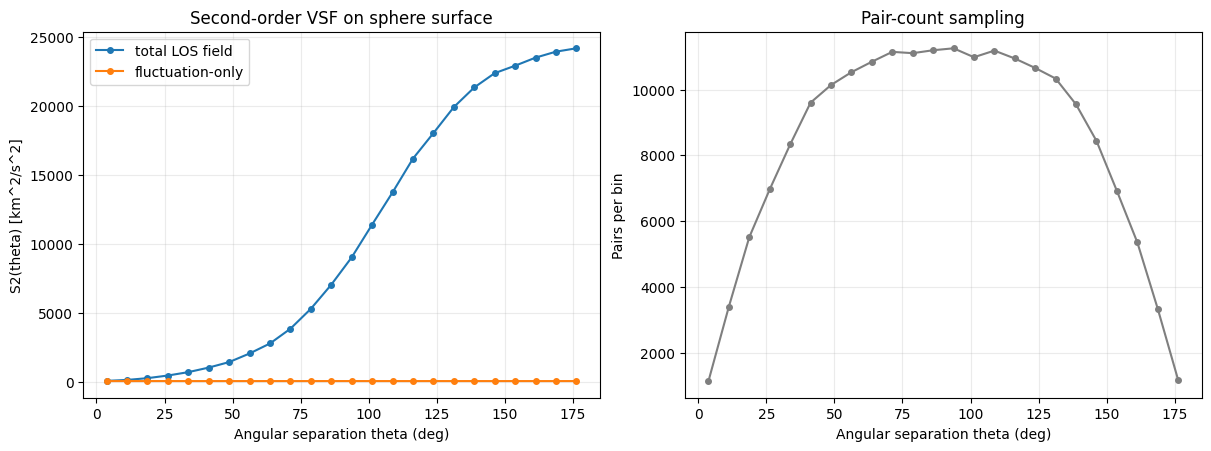

In [35]:
# VSF on the full 3D sphere surface from Cell 5 results
# S2(theta) = < [v_i - v_j]^2 > binned by angular separation theta on the sphere

# Build full-sphere point set from front (+z) and back (-z) surface points
mask = inside
xf = X[mask]
yf = Y[mask]
zf = mu_map[mask]
xb = X[mask]
yb = Y[mask]
zb = -mu_map[mask]

# LOS velocities on front/back surfaces (already includes bulk + fluctuations)
vf = v_front_surface[mask]
vb = v_back_surface[mask]

x3 = np.concatenate([xf, xb])
y3 = np.concatenate([yf, yb])
z3 = np.concatenate([zf, zb])
v3 = np.concatenate([vf, vb])

# Optional: subtract deterministic outward bulk LOS term to get fluctuation-only VSF
vbulk3 = np.concatenate([+v_bulk_mag * zf, -v_bulk_mag * zf])
v3_fluc = v3 - vbulk3

# Monte Carlo pair sampling on the sphere surface
rng = np.random.default_rng(123)
n_pts = v3.size
n_pairs = 200000
i = rng.integers(0, n_pts, size=n_pairs)
j = rng.integers(0, n_pts, size=n_pairs)
neq = i != j
i = i[neq]
j = j[neq]

# Angular separation between points on unit sphere
dot = x3[i] * x3[j] + y3[i] * y3[j] + z3[i] * z3[j]
dot = np.clip(dot, -1.0, 1.0)
theta_sep = np.arccos(dot)  # radians in [0, pi]

# Second-order VSF for total LOS field and fluctuation-only field
dv2_total = (v3[i] - v3[j])**2
dv2_fluc = (v3_fluc[i] - v3_fluc[j])**2

# Bin by angular separation
n_bins = 24
edges = np.linspace(0.0, np.pi, n_bins + 1)
centers = 0.5 * (edges[:-1] + edges[1:])
idx = np.digitize(theta_sep, edges) - 1

S2_total = np.full(n_bins, np.nan)
S2_fluc = np.full(n_bins, np.nan)
Nbin = np.zeros(n_bins, dtype=int)

for k in range(n_bins):
    m = idx == k
    Nbin[k] = np.count_nonzero(m)
    if Nbin[k] > 0:
        S2_total[k] = np.mean(dv2_total[m])
        S2_fluc[k] = np.mean(dv2_fluc[m])

print(f"Sphere points used: {n_pts}")
print(f"Random pairs used: {len(i)}")
print(f"delta_v (target RMS): {delta_v:.2f} km/s")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.4), constrained_layout=True)

ax[0].plot(np.degrees(centers), S2_total, marker='o', ms=4, lw=1.5, label='total LOS field')
ax[0].plot(np.degrees(centers), S2_fluc, marker='o', ms=4, lw=1.5, label='fluctuation-only')
ax[0].set_xlabel('Angular separation theta (deg)')
ax[0].set_ylabel('S2(theta) [km^2/s^2]')
ax[0].set_title('Second-order VSF on sphere surface')
ax[0].grid(alpha=0.25)
ax[0].legend()

ax[1].plot(np.degrees(centers), Nbin, marker='o', ms=4, lw=1.5, color='tab:gray')
ax[1].set_xlabel('Angular separation theta (deg)')
ax[1].set_ylabel('Pairs per bin')
ax[1].set_title('Pair-count sampling')
ax[1].grid(alpha=0.25)

plt.show()

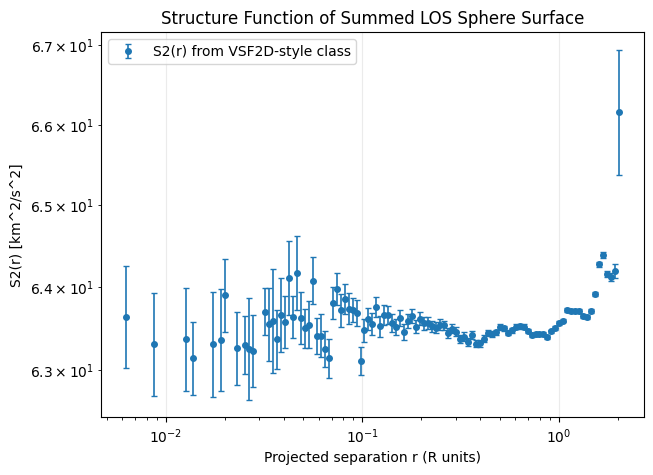

Valid bins: 101/132
Median S2 (finite bins): 63.528 km^2/s^2


In [36]:
# VSF using the same VSF2D-style workflow from Untitled-1.ipynb
from scipy.spatial import cKDTree
from joblib import Parallel, delayed

class VSF2D_Lite:
    def __init__(self, x, y, vel, vel_err=None):
        self.x_physical = np.asarray(x)
        self.y_physical = np.asarray(y)
        self.vel = np.asarray(vel)
        self.vel_err = np.asarray(vel_err) if vel_err is not None else np.zeros_like(self.vel)

    def determine_length(self, r_min, r_max, bin_resolution=5):
        log_range = np.log10(r_max / r_min)
        return max(int(log_range * bin_resolution), 10)

    def generate_bins_2d(self, data, bin_resolution=80, length=None):
        coords = np.column_stack((data['x'], data['y']))
        tree = cKDTree(coords)
        sample_size = min(5000, len(coords))
        sample_idx = np.random.choice(len(coords), sample_size, replace=False)
        dists, _ = tree.query(coords[sample_idx], k=2)
        r_min = np.median(dists[:, 1])

        dx = data['x'].max() - data['x'].min()
        dy = data['y'].max() - data['y'].min()
        r_max = np.sqrt(dx**2 + dy**2)

        if (r_min <= 0) or (r_min >= r_max):
            r_min = r_max / 1000.0
        if length is None:
            length = self.determine_length(r_min, r_max, bin_resolution)

        return np.linspace(np.log10(r_min), np.log10(r_max), length)

    def generate_bins_edges(self, bin_centers):
        bw = np.diff(bin_centers) / 2
        edges = np.empty(len(bin_centers) + 1)
        edges[1:-1] = bin_centers[:-1] + bw
        edges[0] = bin_centers[0] - bw[0]
        edges[-1] = bin_centers[-1] + bw[-1]
        return edges

    def compute_vsf_chunk_2d(self, x, y, vel, vel_err, bin_edges, seed, order):
        rng = np.random.default_rng(seed)
        sample_size = min(12000, len(x))
        idx = rng.choice(len(x), size=sample_size, replace=False)

        x_, y_, vel_, verr_ = x[idx], y[idx], vel[idx], vel_err[idx]
        coords = np.column_stack((x_, y_))
        tree = cKDTree(coords)
        pairs = tree.query_pairs(r=bin_edges[-1], output_type='ndarray')

        nbins = len(bin_edges) - 1
        vsf = np.zeros(nbins)
        vsf_sq = np.zeros(nbins)
        counts = np.zeros(nbins)

        if pairs.size == 0:
            return vsf, vsf_sq, counts

        i, j = pairs[:, 0], pairs[:, 1]
        dr2 = np.sum((coords[i] - coords[j])**2, axis=1)
        dv = vel_[i] - vel_[j]
        dv_p = np.abs(dv)**order

        bin_idx = np.searchsorted(bin_edges**2, dr2) - 1
        valid = (bin_idx >= 0) & (bin_idx < nbins)
        b = bin_idx[valid]

        np.add.at(vsf, b, dv_p[valid])
        np.add.at(vsf_sq, b, dv_p[valid]**2)
        np.add.at(counts, b, 1)

        return vsf, vsf_sq, counts

    def generate_vsf_2d(self, order=2, n_jobs=6, min_pairs=10, bin_resolution=50):
        data = {'x': self.x_physical, 'y': self.y_physical}
        log_centers = self.generate_bins_2d(data, bin_resolution=bin_resolution)
        edges = self.generate_bins_edges(log_centers)
        bin_edges = 10**edges

        nbins = len(bin_edges) - 1
        vsf = np.zeros(nbins)
        vsf_sq = np.zeros(nbins)
        counts = np.zeros(nbins)

        seeds = np.arange(n_jobs)
        results = Parallel(n_jobs=n_jobs)(
            delayed(self.compute_vsf_chunk_2d)(
                self.x_physical, self.y_physical, self.vel, self.vel_err,
                bin_edges, int(seed), order
            ) for seed in seeds
        )

        for vsf_c, vsf_sq_c, cnt_c in results:
            vsf += vsf_c
            vsf_sq += vsf_sq_c
            counts += cnt_c

        with np.errstate(divide='ignore', invalid='ignore'):
            mean = vsf / counts
            mean_sq = vsf_sq / counts
            var = mean_sq - mean**2
            err = np.sqrt(var / counts)

        mean = np.where(counts >= min_pairs, mean, np.nan)
        err = np.where(counts >= min_pairs, err, np.nan)
        return mean, err, log_centers, counts

# Apply to full projected sphere surface (from Cell 5)
mask2 = np.isfinite(v_sum_surface)
x2 = X[mask2]
y2 = Y[mask2]

# VSF of summed LOS map (front+back); this isolates residual fluctuations
vel2 = v_sum_surface[mask2]

vsf_obj = VSF2D_Lite(x2, y2, vel2)
S2, S2_err, logc, counts = vsf_obj.generate_vsf_2d(order=2, n_jobs=6, min_pairs=20, bin_resolution=50)
r = 10**logc

plt.figure(figsize=(7, 5))
plt.errorbar(r, S2, yerr=S2_err, fmt='o', ms=4, lw=1.2, capsize=2, label='S2(r) from VSF2D-style class')
plt.xscale('log')
plt.yscale('log')
plt.xlabel('Projected separation r (R units)')
plt.ylabel('S2(r) [km^2/s^2]')
plt.title('Structure Function of Summed LOS Sphere Surface')
plt.grid(alpha=0.25)
plt.legend()
plt.show()

print(f'Valid bins: {np.count_nonzero(np.isfinite(S2))}/{len(S2)}')
print(f'Median S2 (finite bins): {np.nanmedian(S2):.3f} km^2/s^2')

Thick shell: 0.90 <= r/R <= 1.00, nz=180, npix=150
Thickness=0.10, correlated-noise scale=0.02
Mean(front LOS) = 58.81 km/s
Mean(back  LOS) = -60.88 km/s
Mean(sum   LOS) = -2.08 km/s
RMS(sum LOS)    = 35.20 km/s


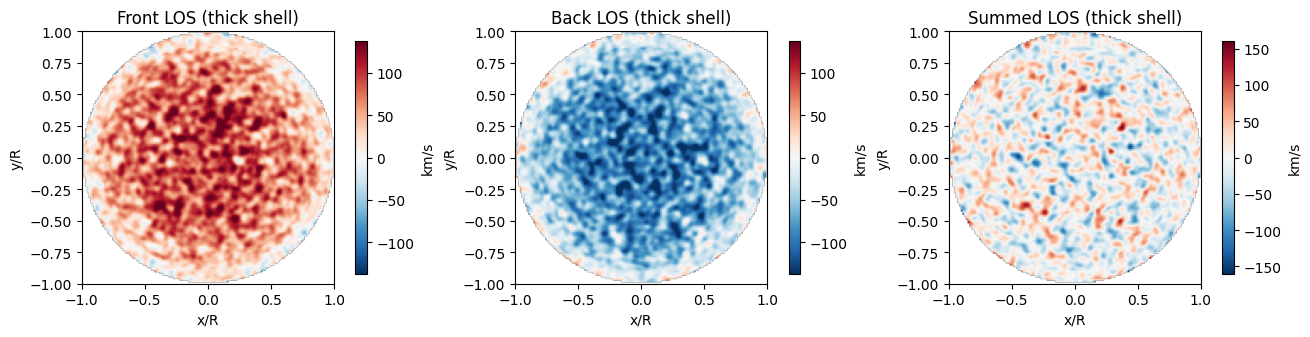

In [65]:
# Thick-shell test: finite 3D shell volume and LOS-integrated velocity maps
from scipy.ndimage import gaussian_filter

v_bulk_mag = 100.0   # km/s outward radial bulk-flow magnitude
delta_v = 40.0        # km/s RMS random fluctuations in the shell volume
r_in = 0.9          # inner radius (R units)
r_out = 1.00         # outer radius (R units)
npix = 150           # sky-plane resolution
nz = 180             # LOS sampling points
seed = 21
corr_frac = 0.2      # correlation length = corr_frac * thickness (capped by thickness)

x = np.linspace(-r_out, r_out, npix)
y = np.linspace(-r_out, r_out, npix)
z = np.linspace(-r_out, r_out, nz)
X, Y = np.meshgrid(x, y, indexing='xy')

p2 = X**2 + Y**2
inside_proj = p2 <= r_out**2

Z = z[None, None, :]
R2 = p2[:, :, None] + Z**2
R = np.sqrt(np.maximum(R2, 1e-12))

# 3D shell mask: only voxels with r_in <= r <= r_out contribute
shell3d = (R2 >= r_in**2) & (R2 <= r_out**2)

# Outward radial flow projected along LOS: v_los = v_bulk_mag * (z/r)
v_bulk_los_3d = v_bulk_mag * (Z / R)

# Correlated 3D fluctuations with upper correlation scale set by shell thickness
thickness = r_out - r_in
corr_len = min(corr_frac * thickness, thickness)
dx = x[1] - x[0]
dy = y[1] - y[0]
dz = z[1] - z[0]
sx = max(corr_len / dx, 0.5)
sy = max(corr_len / dy, 0.5)
sz = max(corr_len / dz, 0.5)

rng = np.random.default_rng(seed)
white = rng.normal(0.0, 1.0, size=R.shape)
corr = gaussian_filter(white, sigma=(sy, sx, sz), mode='reflect')

# Normalize correlated field to target RMS inside shell
corr_shell = corr[shell3d]
corr_std = np.std(corr_shell) if corr_shell.size > 0 else 1.0
noise3d = delta_v * corr / max(corr_std, 1e-12)

v3d = np.where(shell3d, v_bulk_los_3d + noise3d, 0.0)

# Front and back LOS means (depth-averaged on each half)
front_mask = shell3d & (Z > 0)
back_mask = shell3d & (Z < 0)

n_front = np.sum(front_mask, axis=2)
n_back = np.sum(back_mask, axis=2)
v_front_num = np.sum(np.where(front_mask, v3d, 0.0), axis=2)
v_back_num = np.sum(np.where(back_mask, v3d, 0.0), axis=2)
v_front_thick = np.full_like(v_front_num, np.nan, dtype=float)
v_back_thick = np.full_like(v_back_num, np.nan, dtype=float)
np.divide(v_front_num, n_front, out=v_front_thick, where=n_front > 0)
np.divide(v_back_num, n_back, out=v_back_thick, where=n_back > 0)

v_sum_thick = v_front_thick + v_back_thick

# Keep only projected points intersecting the shell
v_front_thick = np.where(inside_proj, v_front_thick, np.nan)
v_back_thick = np.where(inside_proj, v_back_thick, np.nan)
v_sum_thick = np.where(inside_proj, v_sum_thick, np.nan)

print(f"Thick shell: {r_in:.2f} <= r/R <= {r_out:.2f}, nz={nz}, npix={npix}")
print(f"Thickness={thickness:.2f}, correlated-noise scale={corr_len:.2f}")
print(f"Mean(front LOS) = {np.nanmean(v_front_thick):.2f} km/s")
print(f"Mean(back  LOS) = {np.nanmean(v_back_thick):.2f} km/s")
print(f"Mean(sum   LOS) = {np.nanmean(v_sum_thick):.2f} km/s")
print(f"RMS(sum LOS)    = {np.nanstd(v_sum_thick):.2f} km/s")

fig, ax = plt.subplots(1, 3, figsize=(13, 4.2), constrained_layout=True)
extent = [-r_out, r_out, -r_out, r_out]
vals = np.concatenate([v_front_thick[np.isfinite(v_front_thick)], v_back_thick[np.isfinite(v_back_thick)]])
vlim = np.nanpercentile(np.abs(vals), 98)

im0 = ax[0].imshow(v_front_thick, origin='lower', extent=extent, cmap='RdBu_r', vmin=-vlim, vmax=vlim)
ax[0].set_title('Front LOS (thick shell)')
ax[0].set_xlabel('x/R')
ax[0].set_ylabel('y/R')
fig.colorbar(im0, ax=ax[0], fraction=0.046, pad=0.04, label='km/s')

im1 = ax[1].imshow(v_back_thick, origin='lower', extent=extent, cmap='RdBu_r', vmin=-vlim, vmax=vlim)
ax[1].set_title('Back LOS (thick shell)')
ax[1].set_xlabel('x/R')
ax[1].set_ylabel('y/R')
fig.colorbar(im1, ax=ax[1], fraction=0.046, pad=0.04, label='km/s')

vsum_lim = max(2.0, 4.0 * delta_v)
im2 = ax[2].imshow(v_sum_thick, origin='lower', extent=extent, cmap='RdBu_r', vmin=-vsum_lim, vmax=vsum_lim)
ax[2].set_title('Summed LOS (thick shell)')
ax[2].set_xlabel('x/R')
ax[2].set_ylabel('y/R')
fig.colorbar(im2, ax=ax[2], fraction=0.046, pad=0.04, label='km/s')

for a in ax:
    a.set_aspect('equal')

plt.show()

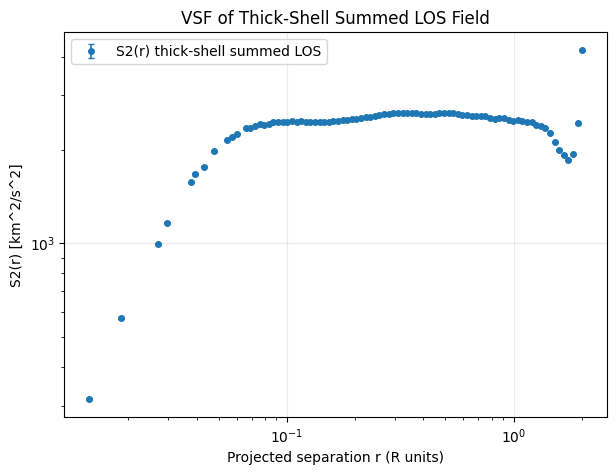

Valid bins: 85/115
Median S2 (finite bins): 2476.299 km^2/s^2


In [66]:
# VSF for thick-shell summed LOS map (same class workflow as above)
if 'VSF2D_Lite' not in globals():
    raise RuntimeError('Run the VSF2D_Lite class cell first (Cell 7).')

m = np.isfinite(v_sum_thick)
x_th = X[m]
y_th = Y[m]
v_th = v_sum_thick[m]

vsf_th = VSF2D_Lite(x_th, y_th, v_th)
S2_th, S2_th_err, logc_th, counts_th = vsf_th.generate_vsf_2d(
    order=2, n_jobs=6, min_pairs=20, bin_resolution=50
)
r_th = 10**logc_th

plt.figure(figsize=(7, 5))
plt.errorbar(
    r_th, S2_th, yerr=S2_th_err, fmt='o', ms=4, lw=1.2, capsize=2,
    label='S2(r) thick-shell summed LOS'
 )
plt.xscale('log')
plt.yscale('log')
plt.xlabel('Projected separation r (R units)')
plt.ylabel('S2(r) [km^2/s^2]')
plt.title('VSF of Thick-Shell Summed LOS Field')
plt.grid(alpha=0.25)
plt.legend()
plt.show()

print(f'Valid bins: {np.count_nonzero(np.isfinite(S2_th))}/{len(S2_th)}')
print(f'Median S2 (finite bins): {np.nanmedian(S2_th):.3f} km^2/s^2')

In [50]:
# VSF comparison for different shell thicknesses with correlated noise
if 'VSF2D_Lite' not in globals():
    raise RuntimeError('Run the VSF2D_Lite cell first.')

from scipy.ndimage import gaussian_filter

# Common setup
v_bulk_mag = 100.0
delta_v = 4.0
r_out = 1.0
npix = 120
nz = 140
seed0 = 40

thickness_list = [0.05, 0.10, 0.20, 0.30, 0.40]  # shell thickness = r_out - r_in
corr_frac = 0.8  # correlation scale = corr_frac * thickness (capped at thickness)

x = np.linspace(-r_out, r_out, npix)
y = np.linspace(-r_out, r_out, npix)
z = np.linspace(-r_out, r_out, nz)
X, Y = np.meshgrid(x, y, indexing='xy')
p2 = X**2 + Y**2
inside_proj = p2 <= r_out**2

Z = z[None, None, :]
R2 = p2[:, :, None] + Z**2
R = np.sqrt(np.maximum(R2, 1e-12))

dx = x[1] - x[0]
dy = y[1] - y[0]
dz = z[1] - z[0]

plt.figure(figsize=(8.4, 5.8))
summary_rows = []

for it, thickness in enumerate(thickness_list):
    r_in = max(0.0, r_out - thickness)
    shell3d = (R2 >= r_in**2) & (R2 <= r_out**2)

    # Outward radial bulk flow projected along LOS
    v_bulk_los_3d = v_bulk_mag * (Z / R)

    # Correlated 3D noise with correlation length limited by shell thickness
    corr_len = min(corr_frac * thickness, thickness)
    sx = max(corr_len / dx, 0.5)
    sy = max(corr_len / dy, 0.5)
    sz = max(corr_len / dz, 0.5)

    rng = np.random.default_rng(seed0 + it)
    white = rng.normal(0.0, 1.0, size=R.shape)
    corr = gaussian_filter(white, sigma=(sy, sx, sz), mode='reflect')

    # Normalize to target RMS inside shell
    corr_shell = corr[shell3d]
    corr_shell_std = np.std(corr_shell) if corr_shell.size > 0 else 1.0
    noise3d = delta_v * corr / max(corr_shell_std, 1e-12)

    v3d = np.where(shell3d, v_bulk_los_3d + noise3d, 0.0)

    front_mask = shell3d & (Z > 0)
    back_mask = shell3d & (Z < 0)

    # Safe depth-averaged LOS means (no empty-slice warnings)
    n_front = np.sum(front_mask, axis=2)
    n_back = np.sum(back_mask, axis=2)
    v_front = np.sum(np.where(front_mask, v3d, 0.0), axis=2)
    v_back = np.sum(np.where(back_mask, v3d, 0.0), axis=2)
    v_front = np.where(n_front > 0, v_front / n_front, np.nan)
    v_back = np.where(n_back > 0, v_back / n_back, np.nan)

    v_sum = np.where(inside_proj, v_front + v_back, np.nan)

    m = np.isfinite(v_sum)
    x_th = X[m]
    y_th = Y[m]
    v_th = v_sum[m]

    vsf_th = VSF2D_Lite(x_th, y_th, v_th)
    S2_th, S2_th_err, logc_th, counts_th = vsf_th.generate_vsf_2d(
        order=2, n_jobs=6, min_pairs=20, bin_resolution=45
    )
    r_th = 10**logc_th

    label = f't={thickness:.2f}, Lcorr={corr_len:.2f}'
    plt.plot(r_th, S2_th, marker='o', ms=3, lw=1.2, label=label)

    summary_rows.append((thickness, corr_len, np.nanmedian(S2_th), np.count_nonzero(np.isfinite(S2_th)), len(S2_th)))

plt.xscale('log')
plt.yscale('log')
plt.xlabel('Projected separation r (R units)')
plt.ylabel('S2(r) [km^2/s^2]')
plt.title('VSF for Different Shell Thicknesses with Correlated Noise')
plt.grid(alpha=0.25)
plt.legend(fontsize=8)
plt.show()

print('Thickness + correlation summary:')
for t, lc, med, n_ok, n_tot in summary_rows:
    print(f'  thickness={t:.2f}, Lcorr={lc:.2f}: median S2={med:.3f} km^2/s^2, valid bins={n_ok}/{n_tot}')

/var/folders/sv/2j0ks0gx2n37tvl2glchkw900000gp/T/ipykernel_63267/2490826701.py:68: RuntimeWarning: invalid value encountered in divide
  v_front = np.where(n_front > 0, v_front / n_front, np.nan)
/var/folders/sv/2j0ks0gx2n37tvl2glchkw900000gp/T/ipykernel_63267/2490826701.py:69: RuntimeWarning: invalid value encountered in divide
  v_back = np.where(n_back > 0, v_back / n_back, np.nan)


KeyboardInterrupt: 

<Figure size 840x580 with 0 Axes>